In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

tranform = transforms.ToTensor()

In [2]:
train_data = datasets.MNIST(
    root = 'data',   # 	Dataset kis folder mein save hoga
    train = True,    # 	Training dataset load karo
    transform = tranform, # 	Image par transformation apply karo
    download = True    # 	Dataset download karo agar available nahi hai
)

test_data = datasets.MNIST(
    root = 'data',
    train = False,  	# Testing dataset load karo
    transform = tranform, #	Image par transformation apply karo
    download = True
)

train_loader = DataLoader(
    train_data,
    batch_size = 64,
    shuffle = True
)
test_loader  = DataLoader(
    test_data,
    batch_size = 64,
    shuffle  = True
)

images, labels = next(iter(train_loader)) #Is line ka kaam hai DataLoader se ek batch of images aur unke labels nikalna.

print(images.shape)
print(labels.shape)

print(len(train_data))
print(len(test_data))

print(labels[:10])  # paheli 10 images ke labels print kro

100%|██████████| 9.91M/9.91M [00:01<00:00, 4.98MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.4MB/s]

torch.Size([64, 1, 28, 28])
torch.Size([64])
60000
10000
tensor([4, 9, 5, 4, 9, 2, 4, 1, 1, 3])


torch.Size([1, 28, 28])
tensor(4)


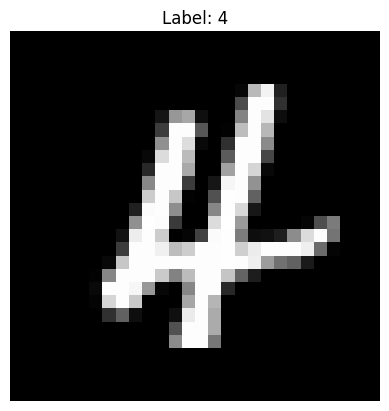

In [3]:
import matplotlib.pyplot as plt

image = images[0]

print(image.shape)
print(labels[0])

plt.imshow(image.squeeze(), cmap='gray')
plt.title(f"Label: {labels[0].item()}")
plt.axis('off')
plt.show()


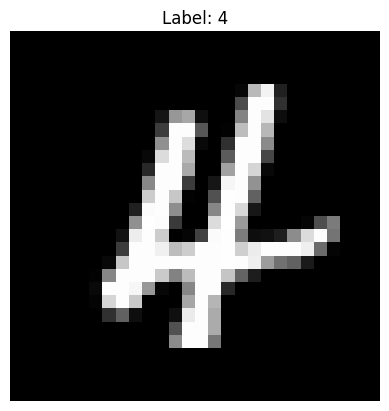

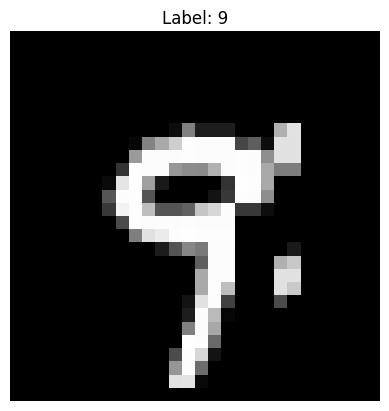

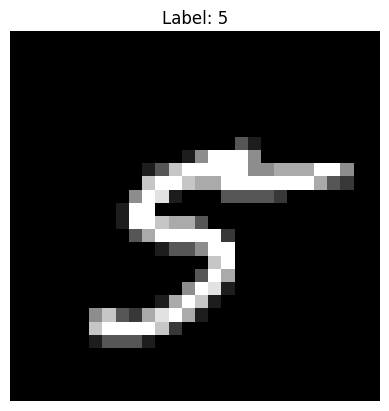

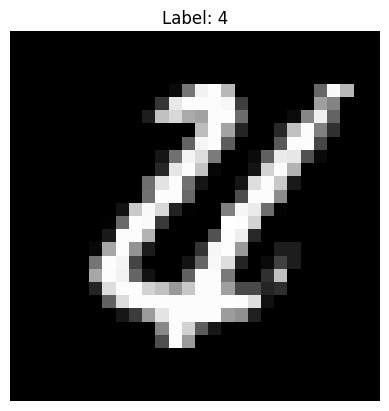

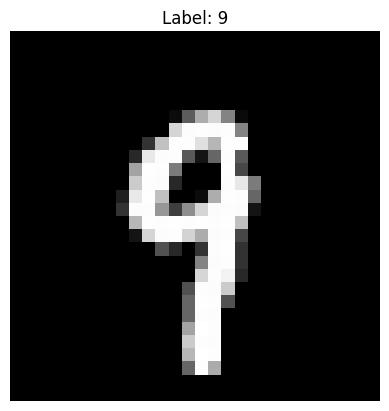

In [4]:
for i in range(5):
  plt.imshow(images[i].squeeze(), cmap='gray')
  plt.title(f"Label: {labels[i].item()}")
  plt.axis('off')
  plt.show()


In [5]:

class MyCNN(nn.Module):

  def __init__(self):
    super().__init__()

    self.con_layer = nn.Sequential(

          nn.Conv2d(1,16, kernel_size = 3, padding = 1),
          nn.ReLU(),
          nn.MaxPool2d(2),

          nn.Conv2d(16,32, kernel_size = 3, padding = 1),
          nn.ReLU(),
          nn.MaxPool2d(2),
    )
    self.fc_layer = nn.Sequential(

         nn.Flatten(),
         nn.Linear(32 * 7 * 7, 128),
         nn.ReLU(),
         nn.Linear(128, 10)
      )

  def forward(self,x):

    x = self.con_layer(x)
    x = self.fc_layer(x)

    return x


model = MyCNN()

loss_functn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)


epochs = 5

# TRAINING LOOP

for epoch in range(epochs):

  model.train()  # Model training mode mein aata hai.

  total_loss = 0

  for images, labels in train_loader:  #Ek batch of 64 images aur labels milte hain

    outputs = model(images)

    loss = loss_functn(outputs, labels)

    optimizer.zero_grad()  # Purane gradients clear hote hain.

    loss.backward()

    optimizer.step()  # Weights update hote hain.

    total_loss += loss.item()

  print(f"Epoch {epoch + 1}, Loss: {total_loss / len(train_loader)}:.4f")




Epoch 1, Loss: 0.224244483589713:.4f
Epoch 2, Loss: 0.06148407240011004:.4f
Epoch 3, Loss: 0.041792682803533564:.4f
Epoch 4, Loss: 0.03321695339307239:.4f
Epoch 5, Loss: 0.025245713332838225:.4f


In [6]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

  for images, labels in test_loader:

    output = model(images)

    predictions = torch.argmax(output, dim = 1)

    total += labels.size(0)

    correct += (predictions == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 98.94%


In [15]:
images, labesls = next(iter(test_loader))

image = images[0]
actu_label = labels[0]

model.eval()

with torch.no_grad():

  output = model(image.unsqueeze(0))
  predicted_label = torch.argmax(output, dim = 1)
  probability = torch.softmax(output, dim = 1)


print("Actual ", actu_label.item())
print("Predicted ", predicted_label.item())
print(probability)



Actual  8
Predicted  9
tensor([[4.3282e-11, 3.4862e-11, 1.5386e-08, 4.0313e-05, 4.6265e-04, 1.2683e-07,
         4.0016e-11, 1.6168e-07, 1.4686e-06, 9.9950e-01]])


In [18]:
wrong_image = []
wrong_label = []
wrong_prediction = []

model.eval()

with torch.no_grad():

  for images, labels in test_loader:

    output = model(images)

    predictions = torch.argmax(output, dim = 1)

    for i in range(len(labels)):

      if predictions[i] != labels[i]:

        wrong_image.append(images[i])
        wrong_label.append(labels[i].item())
        wrong_prediction.append(predictions[i].item())



print("Total Wrong images:" ,len(wrong_image))

Total Wrong images: 106


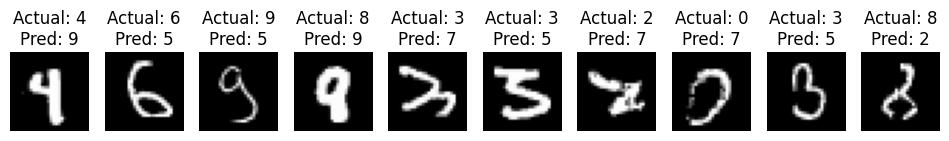

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 10, figsize=(12, 4))

for i in range(10):

    axes[i].imshow(wrong_image[i].squeeze(), cmap="gray")

    axes[i].set_title(
        f"Actual: {wrong_label[i]}\nPred: {wrong_prediction[i]}"
    )

    axes[i].axis("off")

plt.show()

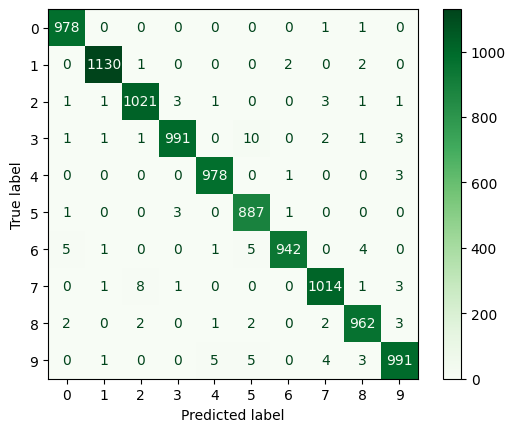

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = []
y_pred = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.tolist())  # extend individualy element add krt ahai list me AND || append ek object add krta hai agar ek list hai to puri list add ho jayegi
        y_pred.extend(predictions.tolist())

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

display.plot(cmap="Greens")
plt.show()

In [26]:
torch.save(model.state_dict(), "mnist_cnn.pth")

loaded_model = MyCNN()

loaded_model.load_state_dict(
    torch.load("mnist_cnn.pth", weights_only=True)
)

loaded_model.eval()